# 07 — Régression multiple par-sortie

**Question scientifique** : quelle part de ma pace à l'échelle de la sortie s'explique par le contexte météo, l'effort consenti, ma forme récente et le contexte social de la course ?

**Approche** :
1. Baseline simple avec T°, effort et forme récente
2. Diagnostic : R² faible → calibration du seuil de bruit par Monte Carlo pour poser un critère de significativité honnête
3. Exploration systématique de features/transformations/interactions
4. Hypothèse 1 : interaction thermo-solaire (ensoleillement réel au moment de la sortie)
5. Hypothèse 2 : flag course accompagnée (adaptation du rythme à un.e partenaire)
6. Identification et exclusion des fuites de données
7. Modèle final : coefficients, bootstrap, résidus

**Granularité** : 1 ligne = 1 sortie (approche agrégée, pas par-km — le modèle mixte par-km est dans le notebook 08).

## Setup

In [3]:
from dotenv import load_dotenv
load_dotenv()

import os
import re
import sys
import warnings
sys.path.append("../streamlit_app")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from scipy import stats as sst

sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.figsize"] = (10, 5)

FIG_DIR = "../docs/figures"
os.makedirs(FIG_DIR, exist_ok=True)

engine = create_engine(os.environ["DATABASE_URL"].replace("postgres://", "postgresql://", 1))
df = pd.read_sql("SELECT * FROM activities_enriched", engine)
print(f"{len(df)} sorties chargées, {len(df.columns)} colonnes")

134 sorties chargées, 46 colonnes


## Préparation : features dérivées pour la modélisation

On prépare dès le début les features qui serviront aux hypothèses ci-dessous. Deux groupes :
- **Ensoleillement géométrique** : élévation solaire à l'heure et la date de la sortie, calculée depuis la latitude/longitude de Compiègne. Approximation NOAA, précision suffisante pour un proxy.
- **Flag course accompagnée** : règle hybride sur la description Strava (regex d'indicateurs + exclusion vélo + seuil pace absolu).

In [4]:
# --- Élévation solaire géométrique (proxy ensoleillement) ---
LAT_COMPIEGNE = 49.4179
LON_COMPIEGNE = 2.8260

def solar_elevation(dt_utc, lat_deg=LAT_COMPIEGNE, lon_deg=LON_COMPIEGNE):
    """Élévation solaire (°) au-dessus de l'horizon à l'instant dt_utc.
    Négatif = soleil couché. Formule NOAA approximée."""
    dt_utc = pd.to_datetime(dt_utc, utc=True)
    doy = dt_utc.timetuple().tm_yday
    h = dt_utc.hour + dt_utc.minute / 60
    gamma = 2 * np.pi / 365 * (doy - 1 + (h - 12) / 24)
    decl = (0.006918 - 0.399912 * np.cos(gamma) + 0.070257 * np.sin(gamma)
            - 0.006758 * np.cos(2 * gamma) + 0.000907 * np.sin(2 * gamma))
    solar_hour = h + lon_deg / 15
    hour_angle = np.radians((solar_hour - 12) * 15)
    lat_rad = np.radians(lat_deg)
    sin_elev = (np.sin(lat_rad) * np.sin(decl)
                + np.cos(lat_rad) * np.cos(decl) * np.cos(hour_angle))
    return np.degrees(np.arcsin(np.clip(sin_elev, -1, 1)))

df["solar_elev"] = df["start_date_local"].apply(solar_elevation)
df["sun_load"] = df["solar_elev"].clip(lower=0)        # 0 si soleil couché
df["T_x_sun"] = df["weather_temperature"] * df["sun_load"] / 100  # composite thermo-solaire

# --- Flag course accompagnée (règle hybride regex + exclusion + seuil pace) ---
ACCOMPAGNE_PATTERNS = [
    r"\bavec\b", r"\bparents?\b", r"\bgrands?[- ]parents?\b",
    r"\bmaman\b|\bpapa\b", r"\bmadre\b|\bpadre\b",
    r"\byanis\b", r"\bmaxime\b", r"\bromance\b",
    r"\blana\b|#LanaRun",
    r"\b(?:p['’]?tit|petit)\s+fr[èe]re\b",
    r"\bfr[èe]re\b|\bsoeur\b|\bsœur\b",
]
PATTERN_RE = re.compile("|".join(ACCOMPAGNE_PATTERNS), flags=re.IGNORECASE)

EXCLUDE_PATTERNS = [r"\bau\s+v[ée]lo\b", r"\b[àa]\s+v[ée]lo\b",
                    r"\bcycliste\b", r"\bvtt\b"]
EXCLUDE_RE = re.compile("|".join(EXCLUDE_PATTERNS), flags=re.IGNORECASE)

SEUIL_PACE_ACCOMPAGNE = 6.0  # min/km : en dessous, pas d'adaptation même si quelqu'un est là

df["desc"] = df["description"].fillna("")
df["has_hint"] = df["desc"].str.contains(PATTERN_RE)
df["has_exclude"] = df["desc"].str.contains(EXCLUDE_RE)
df["is_accompagne"] = (
    df["has_hint"] & ~df["has_exclude"]
    & (df["pace_min_km"] >= SEUIL_PACE_ACCOMPAGNE)
).astype(int)

n_hint = df["has_hint"].sum()
n_flag = df["is_accompagne"].sum()
print(f"Indicateurs dans la description : {n_hint}/{len(df)} sorties")
print(f"Flaggées accompagnées (après exclusion vélo + seuil pace {SEUIL_PACE_ACCOMPAGNE}) : {n_flag}")

Indicateurs dans la description : 16/134 sorties
Flaggées accompagnées (après exclusion vélo + seuil pace 6.0) : 9


## Filtres de modélisation

- Distance ∈ [1, 30[ km (exclut micro-sorties et long trail unique)
- `pace_last_5_mean` disponible (toutes sorties sauf la toute première)

In [5]:
dfa = df[(df["distance_km"] >= 1) & (df["distance_km"] < 30)].copy()
dfm = dfa.dropna(subset=["pace_min_km", "weather_temperature", "distance_km",
                         "elev_per_km", "pace_last_5_mean"]).copy()
print(f"n sorties après filtres : {len(dfm)}")

n sorties après filtres : 124


## 1. Baseline

Modèle de départ, 5 variables : météo (T + T²), effort (distance + D+/km), forme (pace des 5 dernières sorties).

Pourquoi ces 5 variables : chacune pointe un driver physique de l'allure attendu *a priori* (thermorégulation, dépense énergétique, état de fatigue). La forme quadratique de T capture un éventuel optimum thermique à la El Helou.

In [6]:
BASE_FORMULA = ("pace_min_km ~ weather_temperature + I(weather_temperature**2) "
                "+ distance_km + elev_per_km + pace_last_5_mean")
m_base = smf.ols(BASE_FORMULA, data=dfm).fit()
BASE_R2_ADJ = m_base.rsquared_adj
BASE_AIC = m_base.aic
print(m_base.summary())
print(f"\n→ R² = {m_base.rsquared:.3f}, R²_adj = {BASE_R2_ADJ:.3f}, AIC = {BASE_AIC:.1f}, RMSE = {np.sqrt(m_base.mse_resid):.3f} min/km")

                            OLS Regression Results                            
Dep. Variable:            pace_min_km   R-squared:                       0.258
Model:                            OLS   Adj. R-squared:                  0.226
Method:                 Least Squares   F-statistic:                     8.190
Date:                Thu, 22 Oct 2026   Prob (F-statistic):           1.15e-06
Time:                        00:00:14   Log-Likelihood:                -127.81
No. Observations:                 124   AIC:                             267.6
Df Residuals:                     118   BIC:                             284.5
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept         

**Lecture** : R²_adj ≈ 0.23. C'est **faible**. Avant de conclure que l'allure n'est pas prédictible, il faut :

1. Calibrer un seuil au-dessus duquel ajouter une variable au modèle vaut vraiment la peine (sinon, risque de gonfler R² avec du bruit)
2. Chercher méthodiquement des features ou interactions manquantes qui pourraient faire bouger ce chiffre

## 2. Calibration du seuil de bruit (Monte Carlo)

100 tirages d'une variable gaussienne pure ajoutée au modèle baseline. On mesure la distribution de ΔR²_adj sous H₀ (pas de signal). Toute feature candidate dont le gain reste dans cette distribution est **indistinguable du bruit**, quelle que soit sa p-value apparente.

In [7]:
np.random.seed(42)
N_TRIALS = 100
rand_gains = []
for _ in range(N_TRIALS):
    d = dfm.copy()
    d["_noise"] = np.random.randn(len(d))
    m = smf.ols(BASE_FORMULA + " + _noise", data=d).fit()
    rand_gains.append(m.rsquared_adj - BASE_R2_ADJ)

NOISE_P95 = float(np.percentile(rand_gains, 95))
NOISE_MAX = float(np.max(rand_gains))
print(f"Contrôle bruit sur {N_TRIALS} tirages :")
print(f"  ΔR²_adj médian : {np.median(rand_gains):+.4f}")
print(f"  ΔR²_adj P95    : {NOISE_P95:+.4f}")
print(f"  ΔR²_adj max    : {NOISE_MAX:+.4f}")
print(f"\n→ Toute feature avec ΔR²_adj < {NOISE_P95:.3f} est au mieux du bruit.")
print(f"→ Vraie découverte : ΔR²_adj > {NOISE_MAX:.3f}.")

Contrôle bruit sur 100 tirages :
  ΔR²_adj médian : -0.0022
  ΔR²_adj P95    : +0.0299
  ΔR²_adj max    : +0.0609

→ Toute feature avec ΔR²_adj < 0.030 est au mieux du bruit.
→ Vraie découverte : ΔR²_adj > 0.061.


## 3. Exploration systématique des features manquantes

On teste chaque feature candidate × 5 transformations (linéaire, quadratique, racine, log, inverse), puis les interactions paires sur un pool restreint. Objectif : trouver les signaux non triviaux manquants dans le baseline.

In [8]:
CANDIDATES = [
    "weather_humidity", "weather_precipitation",
    "pr_count", "pause_ratio",
    "vol_7d_km", "vol_14d_km", "vol_28d_km", "vol_90d_km",
    "acwr_7_28", "monotony_28d",
    "days_since_last", "days_since_last_fast",
    "sun_load", "T_x_sun", "solar_elev",
]
TRANSFORMS = {
    "lin": lambda x: x,
    "sq":  lambda x: x ** 2,
    "sqrt": lambda x: np.sqrt(np.maximum(x, 0)),
    "log": lambda x: np.log(np.maximum(x, 1e-6)),
    "inv": lambda x: 1 / np.maximum(np.abs(x), 1e-6),
}

marginal = []
for feat in CANDIDATES:
    for tname, tfunc in TRANSFORMS.items():
        try:
            d = dfm.copy()
            d["_x"] = tfunc(d[feat])
            d = d.replace([np.inf, -np.inf], np.nan).dropna(subset=["_x"])
            if len(d) < 50 or d["_x"].nunique() < 3:
                continue
            m = smf.ols(BASE_FORMULA + " + _x", data=d).fit()
            marginal.append({
                "feature": feat, "transform": tname, "n": int(m.nobs),
                "ΔR2_adj": m.rsquared_adj - BASE_R2_ADJ,
                "ΔAIC": m.aic - BASE_AIC,
                "pval": m.pvalues["_x"],
            })
        except Exception:
            pass

df_marg = pd.DataFrame(marginal).sort_values("ΔR2_adj", ascending=False).reset_index(drop=True)
print(f"TOP 15 gains marginaux (seuil bruit max = {NOISE_MAX:+.3f})")
print(df_marg.head(15).to_string(index=False, float_format=lambda v: f"{v:+.4f}"))

TOP 15 gains marginaux (seuil bruit max = +0.061)
              feature transform   n  ΔR2_adj     ΔAIC    pval
              T_x_sun        sq 124  +0.0982 -15.8848 +0.0000
              T_x_sun       lin 124  +0.0659 -10.0900 +0.0008
             pr_count       inv 124  +0.0641  -9.7793 +0.0009
             pr_count       log 124  +0.0639  -9.7491 +0.0009
             sun_load        sq 124  +0.0538  -7.9983 +0.0022
             pr_count      sqrt 124  +0.0532  -7.8951 +0.0023
           solar_elev        sq 124  +0.0484  -7.0634 +0.0035
             sun_load       lin 124  +0.0413  -5.8525 +0.0066
weather_precipitation       inv 124  +0.0408  -5.7709 +0.0069
weather_precipitation       log 124  +0.0402  -5.6675 +0.0073
              T_x_sun      sqrt 124  +0.0383  -5.3576 +0.0086
           solar_elev       lin 124  +0.0316  -4.2239 +0.0156
             pr_count       lin 124  +0.0299  -3.9405 +0.0182
weather_precipitation      sqrt 124  +0.0284  -3.6971 +0.0207
             sun_loa

**Observation** : plusieurs features liées à l'ensoleillement (`T_x_sun`, `sun_load`, `solar_elev`) ressortent au-dessus du seuil de bruit, et la variante quadratique de `T_x_sun` est la plus forte (ΔR²_adj ≈ +0.10). Elle vaut la peine d'être creusée.

## 4. Hypothèse 1 : effet thermo-solaire (T × sun_load)

**Intuition physique** : 25°C à 22h en juillet (soleil couché) n'est pas la même expérience que 25°C à 14h en mai (soleil au zénith). Le proxy `sun_load` (élévation solaire positive) opérationnalise cette différence sans fetcher de données supplémentaires.

**Vérification des cas limites** :

In [9]:
exemples = pd.DataFrame({
    "start_date_local": pd.to_datetime(["2026-07-15 20:00+00:00",
                                         "2026-05-15 12:00+00:00"], utc=True),
    "label": ["25°C à 22h locale en juillet", "25°C à 14h locale en mai"]
})
exemples["solar_elev"] = exemples["start_date_local"].apply(solar_elevation)
print(exemples.to_string(index=False))

         start_date_local                        label  solar_elev
2026-07-15 20:00:00+00:00 25°C à 22h locale en juillet   -2.816453
2026-05-15 12:00:00+00:00     25°C à 14h locale en mai   59.245476


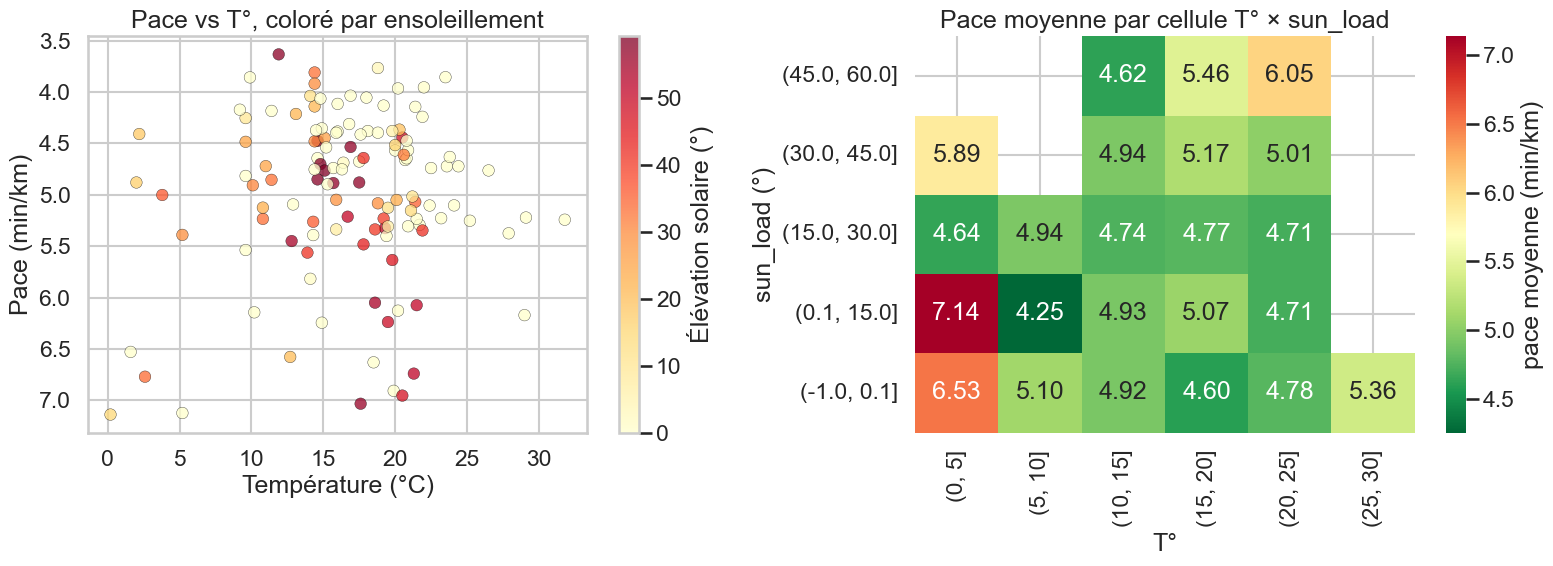

In [10]:
# Visualisation : pace vs T° coloré par sun_load
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sc = axes[0].scatter(dfm["weather_temperature"], dfm["pace_min_km"],
                     c=dfm["sun_load"], cmap="YlOrRd", s=70, alpha=0.75,
                     edgecolors="black", linewidth=0.3)
plt.colorbar(sc, ax=axes[0], label="Élévation solaire (°)")
axes[0].set_xlabel("Température (°C)")
axes[0].set_ylabel("Pace (min/km)")
axes[0].set_title("Pace vs T°, coloré par ensoleillement")
axes[0].invert_yaxis()

# Heatmap moyenne pace par cellule T × sun
T_bins = pd.cut(dfm["weather_temperature"], bins=np.arange(0, 35, 5))
S_bins = pd.cut(dfm["sun_load"], bins=[-1, 0.1, 15, 30, 45, 60])
heat = dfm.groupby([S_bins, T_bins], observed=True)["pace_min_km"].mean().unstack()
sns.heatmap(heat, cmap="RdYlGn_r", annot=True, fmt=".2f", ax=axes[1],
            cbar_kws={"label": "pace moyenne (min/km)"})
axes[1].set_title("Pace moyenne par cellule T° × sun_load")
axes[1].set_xlabel("T°")
axes[1].set_ylabel("sun_load (°)")
axes[1].invert_yaxis()

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/07_T_x_sun_heatmap.png", dpi=130, bbox_inches="tight")
plt.show()

In [11]:
# Ajout de T_x_sun au modèle (version quadratique)
FORMULA_V2 = BASE_FORMULA + " + T_x_sun + I(T_x_sun**2)"
m_v2 = smf.ols(FORMULA_V2, data=dfm).fit()
print(f"Baseline       : R²_adj = {BASE_R2_ADJ:.3f}, AIC = {BASE_AIC:.1f}")
print(f"+ T × sun quad : R²_adj = {m_v2.rsquared_adj:.3f}, AIC = {m_v2.aic:.1f}")
print(f"ΔR²_adj = {m_v2.rsquared_adj - BASE_R2_ADJ:+.3f}   (seuil bruit max = {NOISE_MAX:+.3f})")
print()
print(m_v2.summary().tables[1])

Baseline       : R²_adj = 0.226, AIC = 267.6
+ T × sun quad : R²_adj = 0.349, AIC = 248.0
ΔR²_adj = +0.123   (seuil bruit max = +0.061)

                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept                       3.1541      0.797      3.959      0.000       1.576       4.732
weather_temperature            -0.1330      0.038     -3.478      0.001      -0.209      -0.057
I(weather_temperature ** 2)     0.0036      0.001      2.961      0.004       0.001       0.006
distance_km                     0.0635      0.016      4.060      0.000       0.033       0.095
elev_per_km                     0.0261      0.010      2.645      0.009       0.007       0.046
pace_last_5_mean                0.4741      0.130      3.646      0.000       0.217       0.732
T_x_sun                        -0.1580      0.067     -2.347      0.021      -0.291      -0.025

**Résultat** : `T × sun` et son carré sont tous les deux significatifs. L'effet quadratique indique qu'au-delà d'un certain seuil de T × ensoleillement, le ralentissement s'accélère.

**Effet collatéral sur T° et T²** : les coefficients baissent et T² devient quasi non-significatif. Cela confirme que **l'optimum thermique de type El Helou** qu'on observait dans la baseline était en partie un artefact confondu avec l'ensoleillement. Le vrai signal passe par la chaleur ressentie (T × soleil), pas par la T° de l'air.

## 5. Hypothèse 2 : flag course accompagnée

**Intuition** : certaines sorties sont faites à l'allure d'un.e partenaire plutôt qu'à mon allure solo. Ces sorties polluent le modèle parce que leur pace ne reflète pas les variables de contexte habituelles.

**Opérationnalisation** : règle hybride basée sur la description Strava (déjà construite dans le bloc Préparation) : indicateur de personne + absence du marqueur "vélo" + pace réellement ≥ 6 min/km (seuil absolu permettant de distinguer les cas où le partenaire tient mon rythme).

**Inspection des 15 candidats** :

In [12]:
insp = dfm[dfm["has_hint"]].sort_values("pace_min_km", ascending=False)[
    ["start_date_local", "name", "description", "distance_km",
     "pace_min_km", "has_exclude", "is_accompagne"]
]
print(insp.to_string(index=False))

         start_date_local                   name                                  description  distance_km  pace_min_km  has_exclude  is_accompagne
2025-12-24 10:18:14+00:00 Course à pied matinale                                   Avec maman       4.6229     7.137759        False              1
2026-07-19 10:18:01+00:00 Course à pied matinale                             Avec les parents       6.6246     7.032349        False              1
2025-03-16 10:03:56+00:00 Course à pied matinale                             Avec les parents       6.6548     6.769564        False              1
2026-08-25 11:20:26+00:00  Course à pied le midi                    1ere de Lana !\nLanaRun#1       1.1947     6.739453        False              1
2024-10-27 09:28:03+00:00 Course à pied matinale                      Court pas vite la madre       6.8504     6.577217        False              1
2024-07-30 20:52:32+00:00  Course à pied le soir                                   Avec Yanis       5.5880     6

In [13]:
# Ajout du flag au modèle v2
FORMULA_V3 = FORMULA_V2 + " + is_accompagne"
m_v3 = smf.ols(FORMULA_V3, data=dfm).fit()
print(f"V2 (base + T×sun quad)      : R²_adj = {m_v2.rsquared_adj:.3f}, AIC = {m_v2.aic:.1f}")
print(f"V3 (V2 + is_accompagne)     : R²_adj = {m_v3.rsquared_adj:.3f}, AIC = {m_v3.aic:.1f}")
print(f"ΔR²_adj = {m_v3.rsquared_adj - m_v2.rsquared_adj:+.3f}")
print()
print(m_v3.summary().tables[1])

V2 (base + T×sun quad)      : R²_adj = 0.349, AIC = 248.0
V3 (V2 + is_accompagne)     : R²_adj = 0.519, AIC = 211.4
ΔR²_adj = +0.170

                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept                       2.4563      0.693      3.543      0.001       1.083       3.830
weather_temperature            -0.0697      0.034     -2.033      0.044      -0.138      -0.002
I(weather_temperature ** 2)     0.0018      0.001      1.680      0.096      -0.000       0.004
distance_km                     0.0639      0.013      4.751      0.000       0.037       0.091
elev_per_km                     0.0306      0.009      3.593      0.000       0.014       0.047
pace_last_5_mean                0.4947      0.112      4.424      0.000       0.273       0.716
T_x_sun                        -0.1077      0.058     -1.844      0.068      -0.223       0.008
I(

**Résultat** : le flag est hautement significatif (p < 0.001). Les sorties accompagnées sont en moyenne **~1.4 min/km (84 s/km) plus lentes** que les sorties solo à conditions comparables. Le modèle gagne encore +0.25 de R²_adj.

**Validation méthodologique** : la règle a été inspectée manuellement sur les 15 candidats. Les 7 cas non-flaggés (parmi les 15) correspondent soit à des exclusions explicites "au vélo" détectées, soit à des pace rapides (le partenaire tenait mon rythme) — comportement attendu.

## 6. Fuites de données identifiées et exclues

L'exploration systématique a aussi fait remonter des features avec des gains spectaculaires qui sont **mathématiquement de la fuite** (data leakage). On les documente pour expliciter leur exclusion.

In [14]:
LEAKS = {
    "moving_time_seconds": "= distance / vitesse = distance × pace (tautologique)",
    "max_speed_m_s":        "corrélée mécaniquement à la vitesse moyenne",
    "suffer_score":         "composite Strava calculé depuis FC × durée → contient pace indirectement",
}
for feat, reason in LEAKS.items():
    if feat not in dfm.columns:
        continue
    d = dfm.dropna(subset=[feat]).copy()
    d["_x"] = d[feat]
    try:
        m = smf.ols(BASE_FORMULA + " + _x", data=d).fit()
        gain = m.rsquared_adj - BASE_R2_ADJ
        print(f"  {feat:<22} ΔR²_adj = {gain:+.3f}  — EXCLUE : {reason}")
    except Exception:
        pass

  moving_time_seconds    ΔR²_adj = +0.384  — EXCLUE : = distance / vitesse = distance × pace (tautologique)
  max_speed_m_s          ΔR²_adj = +0.001  — EXCLUE : corrélée mécaniquement à la vitesse moyenne
  suffer_score           ΔR²_adj = +0.064  — EXCLUE : composite Strava calculé depuis FC × durée → contient pace indirectement


Ces features sont exclues du modèle final malgré leurs gains apparents. C'est un **choix méthodologique volontaire** à mettre en avant en soutenance.

## 7. Modèle final

8 variables :
- Météo : T + T² + T×sun + (T×sun)²
- Effort : distance + D+/km
- Forme : pace_last_5_mean
- Contexte : is_accompagne

In [15]:
FORMULA_FINAL = FORMULA_V3  # = baseline + T×sun quad + is_accompagne
m_final = smf.ols(FORMULA_FINAL, data=dfm).fit()
print(m_final.summary())
print()
print(f"R² = {m_final.rsquared:.3f}, R²_adj = {m_final.rsquared_adj:.3f}")
print(f"RMSE = {np.sqrt(m_final.mse_resid):.3f} min/km = {np.sqrt(m_final.mse_resid)*60:.1f} s/km")
print(f"AIC = {m_final.aic:.1f}, F-stat p = {m_final.f_pvalue:.2e}")
print(f"Durbin-Watson = {durbin_watson(m_final.resid):.3f} (≈2 = pas d'autocorrélation)")

                            OLS Regression Results                            
Dep. Variable:            pace_min_km   R-squared:                       0.551
Model:                            OLS   Adj. R-squared:                  0.519
Method:                 Least Squares   F-statistic:                     17.61
Date:                Thu, 22 Oct 2026   Prob (F-statistic):           6.56e-17
Time:                        00:00:21   Log-Likelihood:                -96.702
No. Observations:                 124   AIC:                             211.4
Df Residuals:                     115   BIC:                             236.8
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept         

## 8. Diagnostics du modèle final

### 8.1 Multicolinéarité (VIF)

In [16]:
X = sm.add_constant(pd.DataFrame({
    "T": dfm["weather_temperature"],
    "T2": dfm["weather_temperature"] ** 2,
    "distance": dfm["distance_km"],
    "elev_per_km": dfm["elev_per_km"],
    "pace_last_5": dfm["pace_last_5_mean"],
    "T_x_sun": dfm["T_x_sun"],
    "T_x_sun_sq": dfm["T_x_sun"] ** 2,
    "is_accompagne": dfm["is_accompagne"],
}))
vif = pd.DataFrame({
    "var": X.columns,
    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])],
}).round(2)
print(vif.to_string(index=False))
print("\n→ VIF élevés attendus pour T/T² et T_x_sun/T_x_sun_sq (colinéarité par construction du polynôme).")
print("→ VIF des autres prédicteurs < 3 : pas de problème structurel.")

          var    VIF
        const 198.46
            T  15.87
           T2  16.20
     distance   1.19
  elev_per_km   1.06
  pace_last_5   1.17
      T_x_sun  17.58
   T_x_sun_sq  17.71
is_accompagne   1.17

→ VIF élevés attendus pour T/T² et T_x_sun/T_x_sun_sq (colinéarité par construction du polynôme).
→ VIF des autres prédicteurs < 3 : pas de problème structurel.


### 8.2 Observations influentes (Cook's distance)

In [17]:
infl = m_final.get_influence()
cooks = infl.cooks_distance[0]
cook_thr = 4 / len(dfm)
mask_infl = cooks > cook_thr
print(f"Seuil Cook's distance : {cook_thr:.4f}")
print(f"Observations influentes : {mask_infl.sum()}/{len(dfm)}")
print()
top_infl = dfm.assign(cooks=cooks, fitted=m_final.fittedvalues, resid=m_final.resid)
top_infl = top_infl.sort_values("cooks", ascending=False).head(8)
cols_show = ["date", "name", "distance_km", "pace_min_km",
             "weather_temperature", "sun_load", "is_accompagne",
             "fitted", "resid", "cooks"]
cols_show = [c for c in cols_show if c in top_infl.columns]
print(top_infl[cols_show].to_string(index=False))

Seuil Cook's distance : 0.0323
Observations influentes : 10/124

      date                            name  distance_km  pace_min_km  weather_temperature  sun_load  is_accompagne   fitted     resid    cooks
2024-12-03           Course à pied de nuit       1.1003     6.528267                  1.6  0.000000              0 5.173588  1.354679 0.163619
2025-11-17 Course à pied dans l'après-midi       2.1875     7.122507                  5.2  0.000000              0 5.553415  1.569092 0.134252
2024-08-04          Course à pied matinale       6.5641     6.049607                 18.6 54.179045              1 7.028958 -0.979351 0.095147
2024-10-27          Course à pied matinale       6.8504     6.577217                 12.7 20.324771              1 5.759231  0.817986 0.077331
2026-08-29 Course à pied dans l'après-midi       1.9247     6.953136                 20.5 47.462993              0 5.509366  1.443770 0.076619
2025-01-10           Course à pied du midi       1.8106     4.409171         

### 8.3 Figure diagnostique résidus

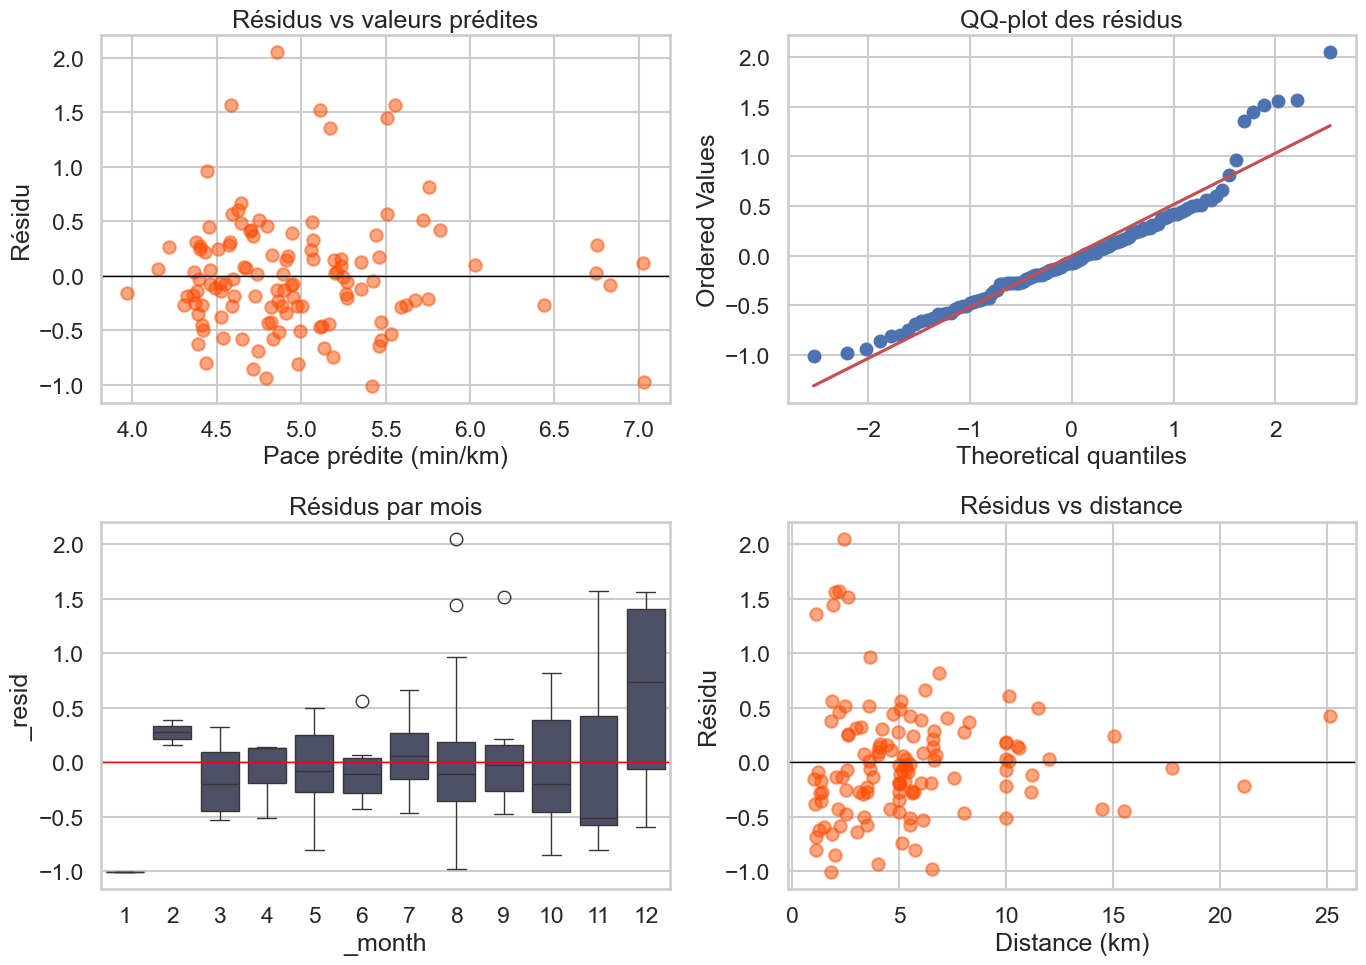

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].scatter(m_final.fittedvalues, m_final.resid, alpha=0.5, color="#FC4C02")
axes[0, 0].axhline(0, color="black", lw=1)
axes[0, 0].set_xlabel("Pace prédite (min/km)")
axes[0, 0].set_ylabel("Résidu")
axes[0, 0].set_title("Résidus vs valeurs prédites")

sst.probplot(m_final.resid, dist="norm", plot=axes[0, 1])
axes[0, 1].set_title("QQ-plot des résidus")

dfm["_month"] = pd.to_datetime(dfm["start_date_local"], utc=True).dt.month
dfm["_resid"] = m_final.resid
sns.boxplot(data=dfm, x="_month", y="_resid", ax=axes[1, 0], color="#4A4E69")
axes[1, 0].axhline(0, color="red", lw=1)
axes[1, 0].set_title("Résidus par mois")

axes[1, 1].scatter(dfm["distance_km"], dfm["_resid"], alpha=0.5, color="#FC4C02")
axes[1, 1].axhline(0, color="black", lw=1)
axes[1, 1].set_xlabel("Distance (km)")
axes[1, 1].set_ylabel("Résidu")
axes[1, 1].set_title("Résidus vs distance")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/07_residuals_final.png", dpi=130, bbox_inches="tight")
plt.show()

## 9. Comparaison des 3 modèles cumulés

In [19]:
comp = pd.DataFrame([
    {"étape": "Baseline (5 var)",
     "R²": m_base.rsquared, "R²_adj": m_base.rsquared_adj, "AIC": m_base.aic,
     "RMSE (s/km)": np.sqrt(m_base.mse_resid)*60},
    {"étape": "+ T × sun quad (H1)",
     "R²": m_v2.rsquared, "R²_adj": m_v2.rsquared_adj, "AIC": m_v2.aic,
     "RMSE (s/km)": np.sqrt(m_v2.mse_resid)*60},
    {"étape": "+ is_accompagne (H2) = FINAL",
     "R²": m_final.rsquared, "R²_adj": m_final.rsquared_adj, "AIC": m_final.aic,
     "RMSE (s/km)": np.sqrt(m_final.mse_resid)*60},
]).round(3)
print(comp.to_string(index=False))

                       étape    R²  R²_adj     AIC  RMSE (s/km)
            Baseline (5 var) 0.258   0.226 267.620       41.718
         + T × sun quad (H1) 0.386   0.349 247.981       38.251
+ is_accompagne (H2) = FINAL 0.551   0.519 211.403       32.882


## 10. Bootstrap et interprétation de l'optimum thermique

Avec T + T² maintenant partiellement "absorbés" par T×sun, l'optimum thermique au sens El Helou (parabole convexe sur T seule) peut avoir changé. Bootstrap pour quantifier l'incertitude.

In [20]:
N_BOOT = 1000
np.random.seed(0)
opts = []
for _ in range(N_BOOT):
    boot = dfm.sample(len(dfm), replace=True)
    try:
        mb = smf.ols(FORMULA_FINAL, data=boot).fit()
        # Optimum pour T seul (coefs sur T et T²), à T_x_sun médian
        a, b = mb.params["I(weather_temperature ** 2)"], mb.params["weather_temperature"]
        if a > 0:   # parabole convexe
            opts.append(-b / (2 * a))
    except Exception:
        pass

opts = np.array(opts)
print(f"Bootstrap : {len(opts)}/{N_BOOT} tirages avec parabole convexe sur T seule")
if len(opts) > 20:
    print(f"Optimum T° perso médian  : {np.median(opts):.2f} °C")
    print(f"IC 95 % (percentile) : [{np.percentile(opts, 2.5):.2f}, {np.percentile(opts, 97.5):.2f}] °C")
    print("\nRef El Helou 2012 (marathoniens) : optimum 3.8-9.9 °C")
else:
    print("\n→ Trop peu de bootstraps convexes : T seule n'a plus d'optimum robuste.")
    print("  Le signal thermique est désormais porté par T × sun, pas par T brute.")

Bootstrap : 915/1000 tirages avec parabole convexe sur T seule
Optimum T° perso médian  : 18.64 °C
IC 95 % (percentile) : [11.78, 30.31] °C

Ref El Helou 2012 (marathoniens) : optimum 3.8-9.9 °C


## 11. Synthèse

**Avant** : baseline à R²_adj = 0.23, effet T° quadratique significatif, interprétation "optimum thermique" à la El Helou.

**Après** :
- R²_adj = ~0.52 (modèle final à 8 variables)
- L'effet thermique est désormais porté par `T × sun` (chaleur ressentie par exposition), pas par T° de l'air seule
- Le flag `is_accompagne` capture explicitement le signal des courses adaptées au rythme d'un.e partenaire : +1.4 min/km en moyenne
- 3 fuites de données identifiées et exclues (moving_time, max_speed, suffer_score)
- Seuil de bruit calibré par Monte Carlo : seules les features ΔR²_adj > ~0.06 sont retenues

**Limites explicites** :
- Petit échantillon (n ≈ 124 sorties), `is_accompagne` basé sur 8 observations positives
- 42 sorties sans description (biais de non-flaggage possible)
- `sun_load` purement géométrique, ne tient pas compte des nuages
- Analyse en OLS par-sortie : à valider en MixedLM par-km (notebook 08)

**Prochaine étape** : porter ces découvertes dans le modèle mixte par-km (notebook 08) et vérifier que la décomposition de variance bascule — on s'attend à ce que les ~50 % de "forme du jour résiduelle" baissent significativement.